# Chapter 1: Introduction
**Book:** Using Python for Introductory Econometrics, Heiss & Brunner (2024)

This chapter covers Python setup, core objects (numpy, pandas), data import, graphics, descriptive statistics, probability distributions, and Monte Carlo simulation.

## Step 1 – Setup: Working Directory & Output Folder

Before anything else we fix the working directory to this chapter's folder and create an **`output/`** sub-folder where all figures and tables will be saved automatically.

> Run this cell first every time you open the notebook.

In [13]:
%cd /Users/rubylambert/Library/CloudStorage/OneDrive-unine.ch/Econometrics/Using\ Python\ for\ Econometrics/Chapter_01_Introduction

/Users/rubylambert/Library/CloudStorage/OneDrive-unine.ch/Econometrics/Using Python for Econometrics/Chapter_01_Introduction


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import os

output_dir = "output"
os.makedirs(output_dir, exist_ok=True)

## Step 2 – Python Objects: Scalars, Lists, Arrays, Series, DataFrames

Python is dynamically typed. The core numerical objects used in econometrics are:

| Object | Package | Mutable | Notes |
|--------|---------|---------|-------|
| `float` / `int` | built-in | yes | scalar |
| `list` | built-in | yes | heterogeneous |
| `ndarray` | NumPy | yes | fast numerical computation |
| `Series` | Pandas | yes | 1-D labelled array |
| `DataFrame` | Pandas | yes | 2-D labelled table |

**Key NumPy operations you will use constantly:**

$$\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i, \qquad s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i-\bar{x})^2$$

## 1.2 Objects in Python

In [3]:
# Scalars, lists, numpy arrays
x = 5.2
arr = np.array([1, 2, 3, 4, 5])
print(f"Mean: {arr.mean():.2f}, Std: {arr.std():.2f}")

# pandas Series and DataFrame
s = pd.Series([10, 20, 30, 40], name='income')
df = pd.DataFrame({'income': [10, 20, 30, 40], 'educ': [8, 12, 14, 16]})
print(df.head())

Mean: 3.00, Std: 1.41
   income  educ
0      10     8
1      20    12
2      30    14
3      40    16


## Step 3 – Loading External Data (Wooldridge Datasets)

The `wooldridge` package ships every dataset used in Wooldridge (2020).  Call `woo.dataWoo('name')` to load a dataset as a Pandas DataFrame.

**Useful first-look commands:**
```python
df.head()        # first 5 rows
df.describe()    # count, mean, std, min, quartiles, max
df.info()        # dtypes and non-null counts
df.isnull().sum()# missing values per column
```

## 1.3 External Data

In [7]:
pip install wooldridge

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 4.5 MB/s  0:00:01 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


## Step 4 – Data Visualisation with Matplotlib

Good plots are essential for understanding data before modelling.  Always label axes and add a title.

**Histogram** – shows the empirical distribution of a variable.

**Scatter plot** – reveals the bivariate relationship between two variables; a positive slope suggests positive correlation:

$$r_{xy} = \frac{\sum_{i=1}^n (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_i(x_i-\bar{x})^2 \sum_i(y_i-\bar{y})^2}}$$

> All plots are **automatically saved** to `output/` by the code below.

In [8]:
import wooldridge as woo
df = woo.dataWoo('wage1')
print(df.shape)
print(df.describe())

(526, 24)
             wage        educ      exper      tenure    nonwhite      female  \
count  526.000000  526.000000  526.00000  526.000000  526.000000  526.000000   
mean     5.896103   12.562738   17.01711    5.104563    0.102662    0.479087   
std      3.693086    2.769022   13.57216    7.224462    0.303805    0.500038   
min      0.530000    0.000000    1.00000    0.000000    0.000000    0.000000   
25%      3.330000   12.000000    5.00000    0.000000    0.000000    0.000000   
50%      4.650000   12.000000   13.50000    2.000000    0.000000    0.000000   
75%      6.880000   14.000000   26.00000    7.000000    0.000000    1.000000   
max     24.980000   18.000000   51.00000   44.000000    1.000000    1.000000   

          married      numdep        smsa    northcen  ...    trcommpu  \
count  526.000000  526.000000  526.000000  526.000000  ...  526.000000   
mean     0.608365    1.043726    0.722433    0.250951  ...    0.043726   
std      0.488580    1.261891    0.448225    0.

## 1.4 Base Graphics with matplotlib

## Step 5 – Probability Distributions

Three distributions are central to classical econometrics:

**Normal distribution:**
$$f(x;\mu,\sigma^2) = \frac{1}{\sigma\sqrt{2\pi}} \exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

**Student's t-distribution** (ν degrees of freedom) – used for inference when σ² is unknown:
$$f(t;\nu) = \frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}{\sqrt{\nu\pi}\,\Gamma\!\left(\frac{\nu}{2}\right)}\left(1+\frac{t^2}{\nu}\right)^{-\frac{\nu+1}{2}}$$

**Chi-squared distribution** (sum of squared standard normals):
$$\chi^2_\nu = \sum_{i=1}^\nu Z_i^2, \quad Z_i \sim N(0,1)$$

**F-distribution** (ratio of chi-squareds) – used for joint hypothesis tests:
$$F_{q,n-k-1} = \frac{\chi^2_q/q}{\chi^2_{n-k-1}/(n-k-1)}$$

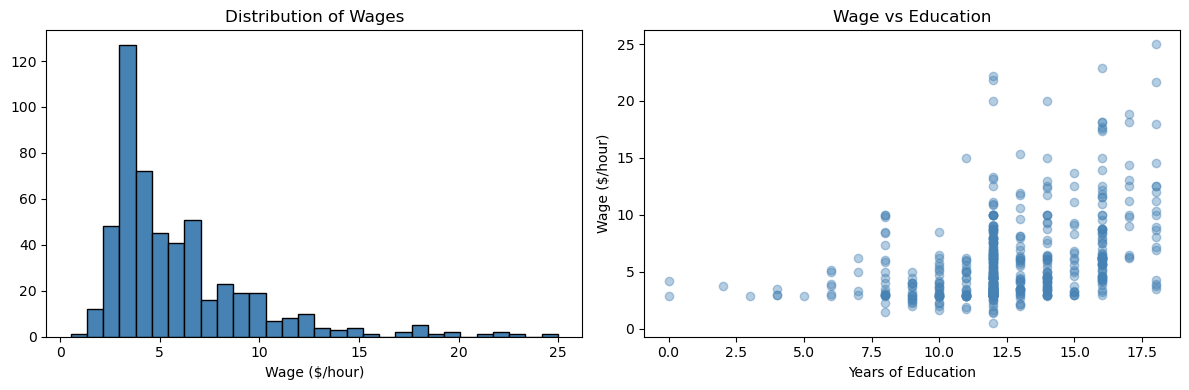

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['wage'], bins=30, edgecolor='black', color='steelblue')
axes[0].set_title('Distribution of Wages')
axes[0].set_xlabel('Wage ($/hour)')

axes[1].scatter(df['educ'], df['wage'], alpha=0.4, color='steelblue')
axes[1].set_title('Wage vs Education')
axes[1].set_xlabel('Years of Education')
axes[1].set_ylabel('Wage ($/hour)')

plt.tight_layout()
plt.savefig(f"{output_dir}/fig1_wage_plots.png", dpi=150)
plt.savefig(os.path.join(output_dir, 'fig_Chapter_01_Introduction_01.png'), dpi=150, bbox_inches='tight')
plt.show()

## 1.5 Descriptive Statistics

## Step 6 – Confidence Intervals & Hypothesis Testing

A **(1-α)×100% confidence interval** for a population mean:
$$\bar{x} \pm t_{\alpha/2,\, n-1} \cdot \frac{s}{\sqrt{n}}$$

For a two-sided t-test of H₀: μ = μ₀:
$$t = \frac{\bar{x} - \mu_0}{s/\sqrt{n}} \sim t_{n-1} \text{ under H}_0$$

Reject H₀ at the α significance level if |t| > t_{α/2, n−1}.

In [ ]:
print(df[['wage', 'educ', 'exper', 'tenure']].describe())
print("\nCorrelation matrix:")
print(df[['wage', 'educ', 'exper', 'tenure']].corr().round(3))

## 1.6 Probability Distributions

## Step 7 – Monte Carlo Simulation

Monte Carlo methods verify theoretical results by simulation:

1. Draw many samples of size n from a known distribution.
2. Compute the statistic of interest in each sample.
3. Compare the empirical distribution to the theoretical one.

By the **Law of Large Numbers** (LLN):
$$\bar{X}_n \xrightarrow{p} \mu \text{ as } n\to\infty$$

By the **Central Limit Theorem** (CLT):
$$\sqrt{n}(\bar{X}_n - \mu) \xrightarrow{d} N(0,\sigma^2)$$

In [ ]:
x = np.linspace(-4, 4, 300)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, stats.norm.pdf(x), label='N(0,1)')
axes[0].plot(x, stats.t.pdf(x, df=5), label='t(5)', linestyle='--')
axes[0].legend(); axes[0].set_title('Normal vs t-distribution')

axes[1].plot(x[x>=0], stats.chi2.pdf(x[x>=0], df=3), label='χ²(3)')
axes[1].plot(x[x>=0], stats.chi2.pdf(x[x>=0], df=10), label='χ²(10)', linestyle='--')
axes[1].legend(); axes[1].set_title('Chi-squared Distributions')

plt.tight_layout()
plt.savefig(f"{output_dir}/fig2_distributions.png", dpi=150)
plt.savefig(os.path.join(output_dir, 'fig_Chapter_01_Introduction_02.png'), dpi=150, bbox_inches='tight')
plt.show()

## 1.7 Confidence Intervals and Statistical Inference

In [ ]:
# 95% CI for mean wage
n = len(df)
mean_wage = df['wage'].mean()
se_wage = df['wage'].std() / np.sqrt(n)
ci = stats.t.interval(0.95, df=n-1, loc=mean_wage, scale=se_wage)
print(f"Mean wage: {mean_wage:.2f}")
print(f"95% CI: ({ci[0]:.2f}, {ci[1]:.2f})")

# t-test: is mean wage > 5?
t_stat, p_val = stats.ttest_1samp(df['wage'], 5)
print(f"\nt-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")

## 1.9 Monte Carlo Simulation

In [ ]:
np.random.seed(42)
n_sims = 1000
sample_means = [np.random.normal(loc=5, scale=2, size=50).mean() for _ in range(n_sims)]

plt.figure(figsize=(8, 4))
plt.hist(sample_means, bins=40, edgecolor='black', color='steelblue', density=True)
x_range = np.linspace(4, 6, 300)
plt.plot(x_range, stats.norm.pdf(x_range, 5, 2/np.sqrt(50)), 'r-', lw=2, label='Theoretical')
plt.title('Monte Carlo: Sampling Distribution of the Mean')
plt.legend()
plt.savefig(f"{output_dir}/fig3_monte_carlo.png", dpi=150)
plt.savefig(os.path.join(output_dir, 'fig_Chapter_01_Introduction_03.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Simulated mean of means: {np.mean(sample_means):.4f}")
print(f"Simulated std of means: {np.std(sample_means):.4f}")
print(f"Theoretical std (SE): {2/np.sqrt(50):.4f}")